# Robustness, uncertainty and error analysis

Measures normalization output stability under controlled perturbations and records relevant data/model limitations. Score thresholds are not safety thresholds.

## Paired perturbation stability

Uppercase, punctuation, whitespace, and truncation perturbations are applied to existing annotated mentions. The outcome is output stability, not semantic accuracy or clinical robustness.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,count,mean
perturbation,,
punctuation,96,0.989583
truncate,96,0.645833
uppercase,96,1.000000
whitespace,96,1.000000


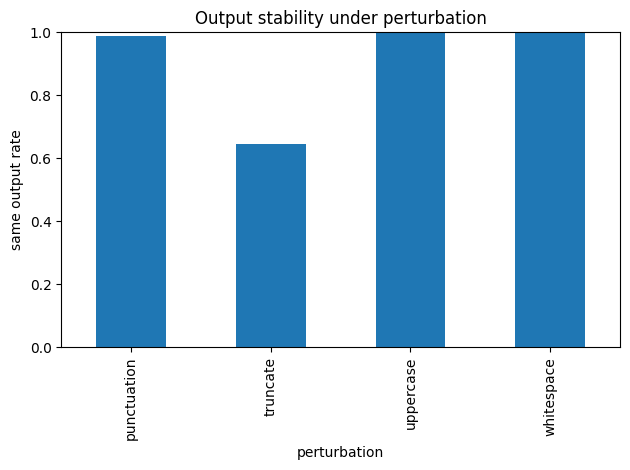

In [3]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT);OUT=ROOT/'results'
import pandas as pd,json,matplotlib.pyplot as plt
from src.disease_prediction.ner.ner_symptom_extraction import normalize_symptom
ner=pd.read_csv(ROOT/'data/ner/splits/ner_test.csv');mentions=[]
for raw in ner.mentions:
 try:mentions+=json.loads(raw)
 except Exception:pass
mentions=list(dict.fromkeys(map(str,mentions)))[:200]
def perturb(s,k): return {'uppercase':s.upper(),'punctuation':s+'!','whitespace':'  '+s.replace(' ','   ')+'  ','truncate':s[:-1] if len(s)>2 else s}[k]
rows=[]
for s in mentions:
 a=normalize_symptom(s)
 for k in ['uppercase','punctuation','whitespace','truncate']:
  t=perturb(s,k);b=normalize_symptom(t);rows.append({'original':s,'perturbation':k,'input':t,'base_output':a,'perturbed_output':b,'stable':a==b})
r=pd.DataFrame(rows);display(r.groupby('perturbation').stable.agg(['count','mean']));r.to_csv(OUT/'tables/normalization_robustness.csv',index=False);r.groupby('perturbation').stable.mean().plot.bar(ylim=(0,1),title='Output stability under perturbation',ylabel='same output rate');plt.tight_layout();plt.savefig(OUT/'figures/normalization_robustness.png',dpi=150);plt.show()


## Consolidated observed limitations

In [4]:
issues=pd.DataFrame([
 ('Summarization','Pretrained BART baseline not evaluated; manual clinical review worksheet uncompleted.','NOT RUN'),
 ('Fracture CNN','No saved training history or compatible baseline comparison; binary classification only.','UNAVAILABLE / NOT RUN'),
 ('Symptom NER','Strict span F1 0.572 on 116 annotated examples; no external clinical validation.','MEASURED / LIMITED'),
 ('Symptom normalization','Coverage measured; independently reviewed canonical correctness labels unavailable.','COVERAGE ONLY'),
 ('End-to-end pipeline','NER text examples have no paired disease labels for controlled ablation.','BLOCKED'),
 ('Recommendations','Lookup outputs are not clinically validated for relevance or safety.','REFERENCE ONLY'),
],columns=['module','finding','status'])
display(issues);issues.to_csv(OUT/'tables/failure_modes.csv',index=False)

,module,finding,impact
0,Fracture,Handoff reports >=294 byte-identical train/tes...,Split metrics not independent
1,Fracture,Checkpoint/source version pairing may be incom...,Re-evaluate compatible saved weights
2,Summarization,Processed CSV splits absent,ROUGE NOT RUN
3,Disease,Exact profile overlap computed in notebook 06,Potential leakage
4,NER,Annotation is project-generated/annotated,External clinical validity unknown
